# 평가 기초 실습: 자르는 자리를 바꿔 두 실행 견주기

**이 노트북에서 할 일**

1. 개발 분할 앞 네 문항을 한 번 검색해 질문마다 정답 문서 자리를 봅니다.
2. 자르는 자리를 받아 세 지표를 내고 기록 한 줄을 만드는 함수를 조립합니다.
3. 자르는 자리 5와 자리 1로 두 번 실행해 기록 두 줄을 나란히 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 다섯 번입니다. 색인 한 벌에 한 번, 질문 검색에 네 번입니다.
답을 쓰는 모델은 이 절에서도 부르지 않습니다.

두 실행은 같은 검색 결과를 다시 씁니다. 그래서 실행이 두 번이어도 요청은 늘지 않습니다.
보낼 조각 수는 색인이 59190개 어림이고 질문은 한 번에 스무 개 안팎입니다.

예상 비용은 다섯 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)의 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 두 갈래이고 모두 실습 묶음에 들어 있습니다.

- 말뭉치 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건과 `labs/data/rag-corpus/manifest.json`
- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`

**이 노트북은 파일을 쓰지 않습니다** — 06절이 `runs` 폴더에 남긴 파일은 읽지도 고치지도 않습니다.
기록 한 줄은 화면에만 냅니다. 파일로 남기는 방법은 06절 8절에서 보았습니다.

**강의와 실습 범위** — 강사와 함께 첫 셀부터 차례로 실행합니다. 따로 내는 과제는 없습니다.
함수를 만드는 셀은 세 개입니다. 01~05절에서 배운 함수는 준비 셀에서 도구 파일로부터 가져옵니다.
3·5절의 재료와 9~11절의 표를 함께 읽습니다.

**기준 버전** — 고정한 패키지는 다섯 개입니다.

- 쪽 읽기: pypdf 6.1.1
- 색인과 임베딩: langchain-core 1.6.2 · langchain-openai 1.6.0
- 코사인 유사도 계산: numpy 2.5.3
- 키 읽기: python-dotenv 1.2.3

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

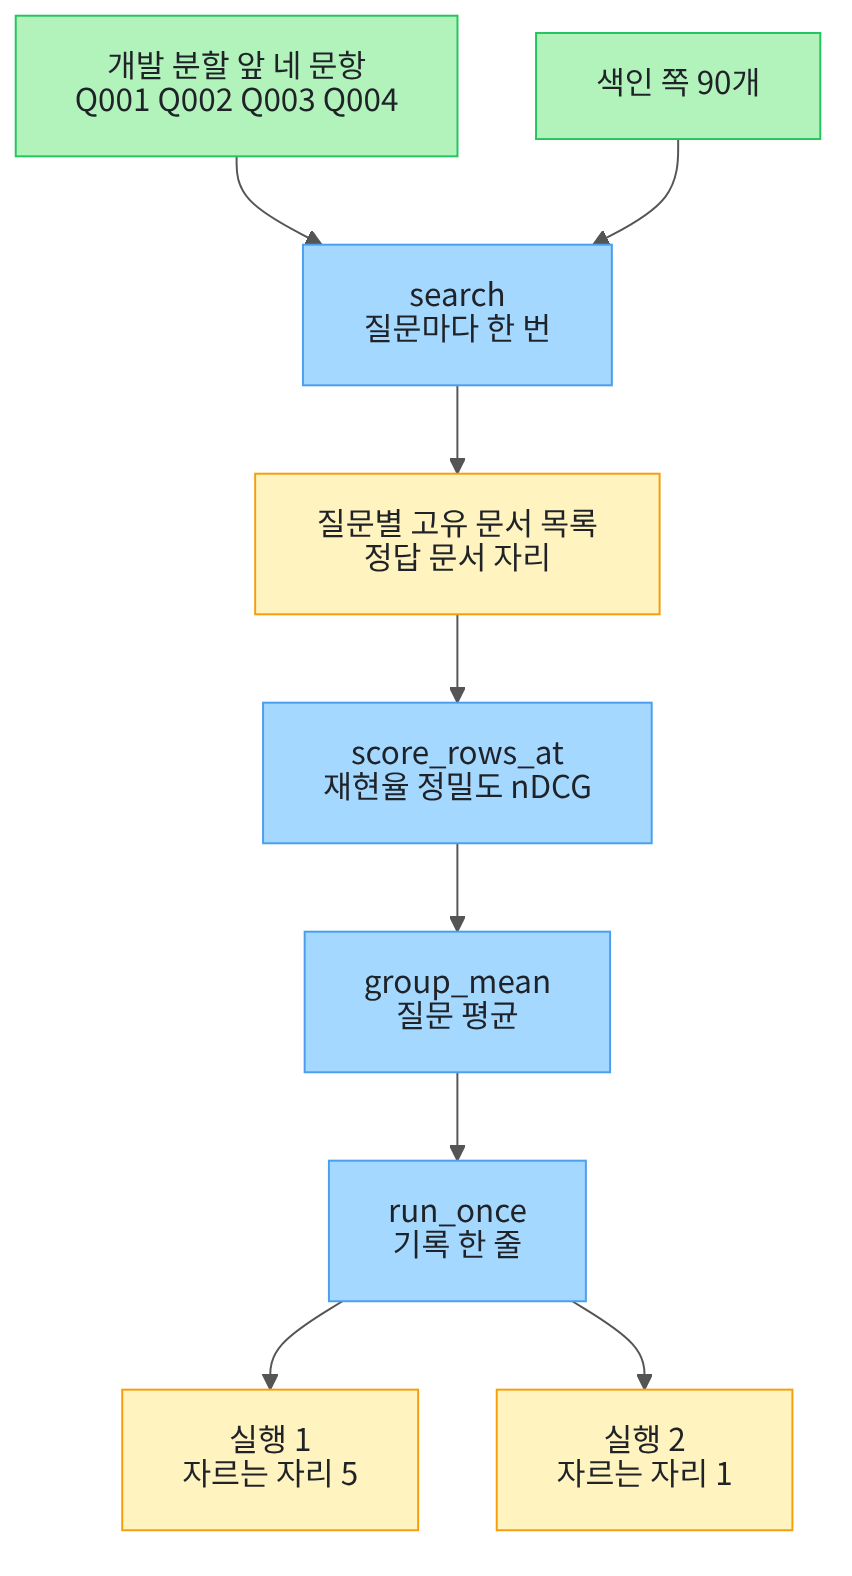

위에서 아래로 읽습니다. 맨 위 초록 상자 둘은 노트북 3·4절에서 만드는 재료입니다.

파란 상자 네 개는 노트북이 부르는 함수입니다. 맨 위와 셋째 상자는 05절 함수를 도구 파일에서 가져옵니다.
둘째와 넷째 상자는 이 절에서 새로 만듭니다.
맨 아래 노란 상자 둘이 이 실습의 두 실행입니다. 두 실행은 자르는 자리 하나만 다릅니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
02~06절에서 쓴 다섯 개와 같습니다. 이 절도 같은 색인을 다시 만들기 때문입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.1.1" "langchain-core==1.6.2" "langchain-openai==1.6.0" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


pypdf: 6.1.1
langchain-core: 1.6.2
langchain-openai: 1.6.0
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 다섯 줄 가운데 첫 줄은 `pypdf: 6.1.1`입니다.
둘째 줄 `langchain-core: 1.6.2`와 셋째 줄 `langchain-openai: 1.6.0`도 보세요.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다. 표준 모듈은 06절 목록에서 둘을 뺀 셋입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 01~05절 함수 일곱 개와 Ch 9 02절 `load_pdf_pages()`를 가져옵니다.
01절 `unique_doc_ids()`·`find_gold_rank()`, 02~04절 `recall_at()`·`precision_at()`·`ndcg_at()`, 05절 `search()`·`group_mean()`입니다.

In [2]:
# 평가셋 읽기·지문 만들기·날짜 적기·색인에 쓸 이름을 불러옵니다
import hashlib
import json
import time

from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
# 01~05절과 Ch 9 02절 함수 여덟 개를 도구 파일에서 가져옵니다
from rag_tools import find_gold_rank, group_mean, load_pdf_pages, ndcg_at
from rag_tools import precision_at, recall_at, search, unique_doc_ids

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.
모듈 `hashlib`은 01·06절에서 파일 지문을 만들 때 쓴 모듈입니다.
모듈 `time`은 06절에서 기록에 날짜를 적을 때 쓴 모듈입니다.

06절이 쓰던 `subprocess`와 `sys`는 부르지 않습니다. 이 절은 다른 프로그램을 실행하지 않습니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 셀은 모듈 `os`도 함께 불러옵니다. 뒤에서 파일이 있는지 볼 때 씁니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~06절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 두 갈래 경로를 만듭니다.
06절이 읽던 앞 챕터 기록 두 갈래는 이 절에서 읽지 않습니다.

In [5]:
# 이 절에서 읽을 파일 두 갈래의 경로를 만듭니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True


**결과 읽기** — 두 줄 모두 `True`입니다.

## 2. 실습 주제 — 자르는 자리를 바꿔 두 실행 견주기

작은 검색 창구의 품질을 재는 일을 맡았다고 봅니다.
같은 색인과 같은 질문으로 값을 내는데, 앞 몇 자리까지 보고 셀지는 사람이 정합니다.
02~05절은 그 자리를 5로 두었고 04절에서 자리 1과 자리 10도 한 번 보았습니다.

이번 실습은 자르는 자리를 바꾼 두 실행을 각각 기록 한 줄로 남겨 견줍니다.
06절에서 만든 기록 한 줄이 그 비교표의 한 줄이 됩니다.

바꾸는 값은 하나입니다. 실행 1은 자르는 자리 5이고 실행 2는 자르는 자리 1입니다.
질문 묶음과 색인, 후보 개수 50, 임베딩 모델은 두 실행에서 같게 둡니다.

## 3. 재료 만들기 — 질문 네 개와 입력 지문

먼저 평가셋 30줄을 읽고 개발 분할 15문항만 남깁니다. 02~06절과 같은 코드입니다.

In [6]:
# 평가셋 30줄을 읽고 설정을 고를 때 쓰는 개발 분할만 남깁니다(06절 2절과 같은 코드)
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))

dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
print("평가셋 줄 수:", len(queries))
print("개발 분할 질문 수:", len(dev_queries))

평가셋 줄 수: 30
개발 분할 질문 수: 15


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`과 `개발 분할 질문 수: 15`입니다.
01~06절에서 본 값과 같습니다.

다음 셀은 그 15문항 가운데 앞 네 문항만 골라 실습 질문 묶음으로 둡니다.
목록 슬라이싱 `[:4]`로 앞에서 네 개를 잘라 냅니다. 요청을 다섯 번으로 줄이려고 질문 수를 줄였습니다.
같은 셀에서 두 실행의 자르는 자리도 미리 정합니다.

In [7]:
# 개발 분할 앞 네 문항을 실습 질문 묶음으로 두고 두 실행의 자르는 자리를 정합니다
small_queries = dev_queries[:4]
small_qids = []
for query in small_queries:
    small_qids.append(query["qid"])
candidate_count = 50
cutoff_narrow = 5
cutoff_top = 1
print("실습 질문 번호:", small_qids)
print("첫 질문 글:", small_queries[0]["question"])
print("후보 개수:", candidate_count)
print("실행 1의 자르는 자리:", cutoff_narrow)
print("실행 2의 자르는 자리:", cutoff_top)

실습 질문 번호: ['Q001', 'Q002', 'Q003', 'Q004']
첫 질문 글: 미르시립도서관의 정기 휴관일은 언제인가요?
후보 개수: 50
실행 1의 자르는 자리: 5
실행 2의 자르는 자리: 1


**결과 읽기** — 첫 줄은 `실습 질문 번호: ['Q001', 'Q002', 'Q003', 'Q004']`입니다.
둘째 줄 `첫 질문 글: 미르시립도서관의 정기 휴관일은 언제인가요?`는 01~06절에서 되풀이해 본 질문입니다.

셋째 줄 `후보 개수: 50`은 02~06절과 같은 값입니다. 이 값을 바꾸면 앞 절 값과 이어지지 않습니다.
넷째 줄과 다섯째 줄이 두 실행에서 다르게 둘 값입니다.

네 문항은 모두 난이도 `easy`이고 정답 문서가 `E01` 하나입니다.
그래서 이 절의 평균은 01~06절 15문항 평균과 다른 값이 나옵니다.

다음 셀은 평가셋 파일의 지문과 기록에 적을 날짜를 만듭니다. 06절 6·7절과 같은 방법입니다.

In [8]:
# 평가셋 파일 지문과 기록에 적을 날짜를 미리 만들어 둡니다(06절 6·7절과 같은 방법)
with open(dataset_path, "rb") as dataset_bytes:
    dataset_fingerprint = hashlib.sha256(dataset_bytes.read()).hexdigest()

run_day = time.strftime("%Y%m%d")
run_date_text = time.strftime("%Y-%m-%d")
print("평가셋 지문 앞 10자:", dataset_fingerprint[:10])
print("기록에 적을 날짜:", run_date_text)

평가셋 지문 앞 10자: 9544b332d5
기록에 적을 날짜: 2026-09-21


**결과 읽기** — 첫 줄은 `평가셋 지문 앞 10자: 9544b332d5`입니다.
01·06절에서 본 값과 같습니다. 평가셋 파일이 그대로라는 뜻입니다.
둘째 줄은 이 노트북을 실행한 날입니다. 교재 출력은 2026-09-21입니다.

## 4. 색인 만들기

02~06절과 같은 다섯 셀입니다. 같은 색인을 다시 만들어야 이 절 값이 앞 절 값과 이어집니다.
먼저 말뭉치 목록에서 스캔 변형을 뺍니다.

In [9]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다(06절 4절과 같은 코드)
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))

목록의 전체 행 수: 21
디지털 PDF 수: 18


**결과 읽기** — 출력 줄은 `목록의 전체 행 수: 21`과 `디지털 PDF 수: 18`입니다.
02~06절에서 본 값과 같습니다.

다음 셀은 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.
읽기는 준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`가 맡습니다.
메타데이터 칸 이름은 Ch 10 01절에서 정한 `doc_id`·`page`·`source`입니다.

In [10]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다(06절 4절과 같은 코드)
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))

읽은 문서 수: 18
읽은 쪽 수: 93


**결과 읽기** — 출력 줄은 `읽은 문서 수: 18`과 `읽은 쪽 수: 93`입니다.
02~06절과 같은 값입니다.

다음 셀은 글자 층이 빈 쪽을 빼고 색인 재료를 고릅니다.

In [11]:
# 글자 층이 빈 쪽을 빼고 색인 재료를 고른 뒤 글이 있는 문서 수를 셉니다(06절 4절과 같은 코드)
index_pages = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) > 0:
        index_pages.append(page_document)
        if page_document.metadata["doc_id"] not in text_doc_ids:
            text_doc_ids.append(page_document.metadata["doc_id"])
print("색인에 넣을 쪽 수:", len(index_pages))
print("글이 있는 문서 수:", len(text_doc_ids))

색인에 넣을 쪽 수: 90
글이 있는 문서 수: 17


**결과 읽기** — 출력 줄은 `색인에 넣을 쪽 수: 90`과 `글이 있는 문서 수: 17`입니다.
읽은 쪽 93개에서 세 쪽이 빠졌습니다. 글자 층이 비는 것을 Ch 10 08절에서 확인한 쪽입니다.

다음 셀은 임베딩 모델을 준비하고 쪽 90개로 색인 한 벌을 만듭니다.
여기서 임베딩 요청 한 번이 나갑니다.

In [12]:
# 임베딩 모델을 준비하고 쪽 Document 90개로 색인 한 벌을 만듭니다(06절 4절과 같은 코드)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
store.add_documents(index_pages)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("색인에 들어간 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
색인에 들어간 항목 수: 90


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
둘째 줄 `차원 수를 주었는가: False`는 Ch 10 07절에서 정한 기본 설정으로 벡터를 만들었다는 뜻입니다.
셋째 줄 `색인에 들어간 항목 수: 90`은 앞 셀에서 고른 쪽 수와 같습니다.
이 노트북의 출력은 2026-09-21에 이 임베딩 모델로 실행한 결과입니다.

## 5. 검색해서 정답 문서 자리 보기

검색은 준비 셀에서 가져온 05절 함수 `search()`로 합니다.
셋째 인자 볼 자리 수와 넷째 인자 후보 개수를 모두 50으로 주어 고유 문서 목록을 자르지 않고 받습니다.
정답 문서 자리는 01절 함수 `find_gold_rank()`로 찾습니다.
자리 `0`은 고유 문서 목록 어디에도 정답 문서가 없다는 뜻입니다.

다음 셀이 이 노트북에서 요청을 보내는 마지막 자리입니다.
질문 네 개를 차례로 검색하고 정답 문서 자리도 함께 모읍니다.
반복문 안에서는 담기만 하고 끝난 뒤에 한꺼번에 출력합니다.

실행 전에 예상합니다. 01~06절과 같은 색인이므로 Q001의 앞 5자리가 앞 절과 같을 것입니다.

In [13]:
# 네 문항을 차례로 검색해 고유 문서 목록과 정답 문서 자리를 함께 모읍니다(임베딩 요청 4번)
unique_by_qid = {}
rank_by_qid = {}
for query in small_queries:
    query_hits = search(store, query["question"], candidate_count, candidate_count)
    doc_ids = unique_doc_ids(query_hits)
    unique_by_qid[query["qid"]] = doc_ids
    rank_by_qid[query["qid"]] = find_gold_rank(doc_ids, query["gold_doc_ids"])
print("검색한 질문 수:", len(unique_by_qid))
print("질문 Q001의 앞 5자리:", unique_by_qid["Q001"][:cutoff_narrow])
print("질문 번호별 정답 문서 자리:", rank_by_qid)

검색한 질문 수: 4
질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']
질문 번호별 정답 문서 자리: {'Q001': 1, 'Q002': 1, 'Q003': 3, 'Q004': 3}


**결과 읽기** — 첫 줄은 `검색한 질문 수: 4`입니다.
둘째 줄은 `질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']`입니다.
02~06절 노트북에서 본 목록과 같습니다. 예상한 대로입니다.

셋째 줄은 `질문 번호별 정답 문서 자리: {'Q001': 1, 'Q002': 1, 'Q003': 3, 'Q004': 3}`입니다.
네 질문 가운데 둘은 정답 문서가 첫 자리에 있고 둘은 셋째 자리에 있습니다.
이 차이가 자르는 자리를 바꿀 때 값을 가르는 자리입니다.

받은 개수는 이 절에서도 출력하지 않습니다.
후보 50개의 뒤쪽 순서가 실행마다 달라져 고유 문서 수가 한두 개 움직이기 때문입니다.

## 6. 앞 절 지표 함수 가져오기

02~04절 지표 함수와 05절 묶음 평균 함수는 준비 셀에서 도구 파일로부터 가져왔습니다. 이 절은 지표 공식을 바꾸지 않습니다.
세 지표 함수 `recall_at()`·`precision_at()`·`ndcg_at()`은 모두 `doc_ids`와 `gold_doc_ids`와 `cutoff`를 받습니다.
인자 모양이 같아 한 반복문에서 세 값을 함께 낼 수 있습니다.

묶음 평균 함수 `group_mean()`은 담아 둔 줄과 지표 칸 이름을 받아 질문 평균을 냅니다.
이제 앞 절에서 배운 함수가 모두 준비됐습니다.

## 7. 기록 장치 — 질문별 표

값을 눈으로 읽으려면 한 줄씩 같은 칸 순서로 나와야 합니다.
Ch 9 07절 `print_rows()`와 Ch 10 09절 `print_hit_rows()`가 있던 자리의 기록 장치입니다.
라벨 줄은 함수 안에서 먼저 출력합니다.

In [14]:
# 질문별 줄을 라벨 줄 아래에 한 줄씩 같은 칸 순서로 출력합니다
def print_score_rows(rows):
    print("질문 번호 | 정답 문서 자리 | 재현율 | 정밀도 | nDCG")
    for row in rows:
        print(row["질문 번호"], "|", row["정답 문서 자리"], "|", row["재현율"], "|", row["정밀도"], "|", row["nDCG"])

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
칸 이름은 05절 질문별 표에서 쓴 한국어 이름을 그대로 씁니다.

## 8. 조립 — 자르는 자리를 받아 기록 한 줄 만들기

이제 앞 절 부품을 하나로 잇습니다. 먼저 자르는 자리를 받아 질문별 줄을 만드는 함수입니다.
질문마다 고유 문서 목록과 정답 문서 ID를 꺼내 세 지표를 함께 냅니다.

In [15]:
# 자르는 자리를 받아 질문마다 세 지표를 낸 줄 목록을 만듭니다(02·03·04절 함수를 함께 부름)
def score_rows_at(cutoff):
    rows = []
    for query in small_queries:
        doc_ids = unique_by_qid[query["qid"]]
        gold_ids = query["gold_doc_ids"]
        row = {"질문 번호": query["qid"], "정답 문서 자리": rank_by_qid[query["qid"]]}
        row["재현율"] = recall_at(doc_ids, gold_ids, cutoff)
        row["정밀도"] = precision_at(doc_ids, gold_ids, cutoff)
        row["nDCG"] = ndcg_at(doc_ids, gold_ids, cutoff)
        rows.append(row)
    return rows

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
검색은 5절에서 이미 끝났습니다. 이 함수는 담아 둔 목록만 읽으므로 요청을 보내지 않습니다.

다음 셀이 이 실습의 조립 함수입니다.
질문별 줄을 만들고 세 지표의 질문 평균을 낸 뒤 06절 모양의 기록 한 줄로 담습니다.

In [16]:
# 자르는 자리를 받아 질문별 줄과 06절 모양의 기록 한 줄을 함께 냅니다
def run_once(run_name, cutoff):
    rows = score_rows_at(cutoff)
    scores = {"재현율": group_mean(rows, "재현율"), "정밀도": group_mean(rows, "정밀도")}
    scores["nDCG"] = group_mean(rows, "nDCG")
    record = {"실행 ID": run_name + "-" + run_day, "실행 날짜": run_date_text}
    record["지표 규칙 이름"] = "고유 문서 기준 질문 평균 v1"
    record["자르는 자리"] = cutoff
    record["질문 수"] = len(rows)
    record["입력 지문"] = dataset_fingerprint[:10]
    record["지표"] = scores
    return {"기록": record, "질문별": rows}

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.

기록 한 줄의 칸은 일곱 개입니다. 실행 ID와 실행 날짜, 지표 규칙 이름, 자르는 자리, 질문 수, 입력 지문, 지표입니다.
06절 기록에 있던 실행 설정 덩어리는 이 절에서 자르는 자리 한 칸으로 줄였습니다.
두 실행에서 달라지는 설정이 그 한 칸뿐이기 때문입니다.

## 9. 실행 1 — 자르는 자리 5

첫 실행은 02~05절과 같은 자리입니다. 앞 다섯 자리까지 보고 셉니다.

실행 전에 예상합니다. 네 질문 모두 정답 문서가 앞 다섯 자리 안에 있어 재현율이 `1.0`일 것입니다.

In [17]:
# 실행 1: 자르는 자리 5로 질문별 표와 기록 한 줄을 냅니다
run1 = run_once("cut5", cutoff_narrow)
print_score_rows(run1["질문별"])
print("실행 1의 기록 한 줄:")
print(json.dumps(run1["기록"], ensure_ascii=False, indent=2))

질문 번호 | 정답 문서 자리 | 재현율 | 정밀도 | nDCG
Q001 | 1 | 1.0 | 0.2 | 1.0
Q002 | 1 | 1.0 | 0.2 | 1.0
Q003 | 3 | 1.0 | 0.2 | 0.5
Q004 | 3 | 1.0 | 0.2 | 0.5
실행 1의 기록 한 줄:
{
  "실행 ID": "cut5-20260921",
  "실행 날짜": "2026-09-21",
  "지표 규칙 이름": "고유 문서 기준 질문 평균 v1",
  "자르는 자리": 5,
  "질문 수": 4,
  "입력 지문": "9544b332d5",
  "지표": {
    "재현율": 1.0,
    "정밀도": 0.2,
    "nDCG": 0.75
  }
}


**결과 읽기** — 라벨 줄 아래 첫 줄은 `Q001 | 1 | 1.0 | 0.2 | 1.0`입니다.
셋째 줄 `Q003 | 3 | 1.0 | 0.2 | 0.5`는 정답 문서가 셋째 자리에 있던 질문입니다.
재현율은 두 줄이 같고 nDCG만 갈립니다. 자리를 값에 넣는 지표가 nDCG이기 때문입니다.

라벨 줄 `실행 1의 기록 한 줄:` 아래에 칸 일곱 개가 보입니다.
칸 `"자르는 자리": 5`와 `"질문 수": 4`가 그 가운데 둘입니다.
지표 칸은 `"재현율": 1.0`과 `"정밀도": 0.2`와 `"nDCG": 0.75`입니다.

이 세 값은 01~06절 15문항 값과 다릅니다. 질문 묶음이 네 문항으로 작기 때문입니다.

## 10. 실행 2 — 자르는 자리 1

이제 값 하나만 바꿉니다. 자르는 자리를 1로 두고 1위만 보고 셉니다.
질문 묶음과 색인, 후보 개수, 임베딩 모델은 실행 1과 같습니다.

실행 전에 예상합니다. 정답 문서가 셋째 자리인 두 질문은 세 값이 모두 `0.0`일 것입니다.

In [18]:
# 실행 2: 자르는 자리만 1로 바꿔 같은 검색 결과로 다시 냅니다
run2 = run_once("cut1", cutoff_top)
print_score_rows(run2["질문별"])
print("실행 2의 기록 한 줄:")
print(json.dumps(run2["기록"], ensure_ascii=False, indent=2))

질문 번호 | 정답 문서 자리 | 재현율 | 정밀도 | nDCG
Q001 | 1 | 1.0 | 1.0 | 1.0
Q002 | 1 | 1.0 | 1.0 | 1.0
Q003 | 3 | 0.0 | 0.0 | 0.0
Q004 | 3 | 0.0 | 0.0 | 0.0
실행 2의 기록 한 줄:
{
  "실행 ID": "cut1-20260921",
  "실행 날짜": "2026-09-21",
  "지표 규칙 이름": "고유 문서 기준 질문 평균 v1",
  "자르는 자리": 1,
  "질문 수": 4,
  "입력 지문": "9544b332d5",
  "지표": {
    "재현율": 0.5,
    "정밀도": 0.5,
    "nDCG": 0.5
  }
}


**결과 읽기** — 라벨 줄 아래 첫 줄은 `Q001 | 1 | 1.0 | 1.0 | 1.0`입니다.
셋째 줄은 `Q003 | 3 | 0.0 | 0.0 | 0.0`입니다. 예상한 대로입니다.

라벨 줄 `실행 2의 기록 한 줄:` 아래 지표 칸은 `"재현율": 0.5`와 `"정밀도": 0.5`와 `"nDCG": 0.5`입니다.
세 값이 모두 같습니다. 정답 문서가 한 개이고 자르는 자리가 1이면 세 공식이 같은 수를 내기 때문입니다.
04절에서 자리 1의 세 값이 모두 `0.6`이었던 것과 같은 모양입니다.

## 11. 두 실행 비교

두 기록을 한 표로 모아 나란히 봅니다. 06절 기록 한 줄이 비교표의 한 줄이 되는 자리입니다.

실행 전에 예상합니다. 자리를 좁혔으니 정밀도는 오르고 재현율과 nDCG는 내려갈 것입니다.

In [19]:
# 두 실행의 기록을 한 표로 모아 나란히 봅니다
run_records = [run1["기록"], run2["기록"]]
print("실행 ID | 자르는 자리 | 질문 수 | 입력 지문 | 재현율 | 정밀도 | nDCG")
for record in run_records:
    scores = record["지표"]
    print(record["실행 ID"], "|", record["자르는 자리"], "|", record["질문 수"], "|", record["입력 지문"], "|", scores["재현율"], "|", scores["정밀도"], "|", scores["nDCG"])

실행 ID | 자르는 자리 | 질문 수 | 입력 지문 | 재현율 | 정밀도 | nDCG
cut5-20260921 | 5 | 4 | 9544b332d5 | 1.0 | 0.2 | 0.75
cut1-20260921 | 1 | 4 | 9544b332d5 | 0.5 | 0.5 | 0.5


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
위 줄은 `| 5 | 4 | 9544b332d5 | 1.0 | 0.2 | 0.75`로 끝나고 아래 줄은 `| 1 | 4 | 9544b332d5 | 0.5 | 0.5 | 0.5`로 끝납니다.
예상한 대로 정밀도만 올라갔습니다.

질문 수와 입력 지문은 두 줄이 같습니다. 같은 질문 묶음과 같은 평가셋으로 잰 값이라는 뜻입니다.
이 두 칸이 다르면 지표 값만 보고 견주기 어렵습니다.

자르는 자리를 좁히면 앞자리 정확도는 올라가고 뒤에 있던 정답 문서는 빠집니다.
이번 네 문항에서는 정답 문서가 셋째 자리인 두 질문이 실행 2에서 값 `0.0`을 받았습니다.

## 12. 정리

1. 같은 검색 결과로도 자르는 자리를 바꾸면 세 지표 값이 함께 달라집니다.
2. 실행마다 설정과 질문 수와 입력 지문을 기록 한 줄에 담아야 두 값을 견줄 수 있습니다.
3. 이번 네 문항에서 자리를 5에서 1로 좁히자 정밀도는 `0.2`에서 `0.5`로 올랐고 재현율과 nDCG는 내려갔습니다.

이 절로 Ch 11이 끝납니다. Ch 12에서는 검색 설정 여러 가지를 같은 질문과 정답으로 견줍니다.